[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_17/MFM_ch17_windows/MFM_ch17_windows.ipynb)

# MFM_ch17_windows

The windows behind ADF, SADF (Phillips, Wu and Yu 2011) and GSADF (Phillips, Shi and Yu 2015), and the Monte Carlo null distributions of the three statistics for T = 440.

*Modelling Financial Markets (MFM), Chapter 17: Bubbles and Crashes. Author: Daniel Traian Pele.*

In [1]:
# Colab: !pip install xlrd
import io
import json
import os
import re
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from scipy import optimize, stats
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [2]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'
Magenta  = '#D63384'
Brown    = '#795548'

HERE = '.'
SEED = 42
R_MC = 2000
# Computing the confidence indicator takes several minutes; set RECOMPUTE = True to recompute it, otherwise precomputed values are used.
RECOMPUTE = False
QL_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/Quantlets/Ch_17/'


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend(fig, axes, ncol=3, y=0.0):
    """One legend for a multi-panel figure, below the figure."""
    h, l = [], []
    for ax in np.atleast_1d(axes):
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l and not ll.startswith('_'):
                h.append(hh)
                l.append(ll)
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer, np.bool_)):
        return o.item()
    if isinstance(o, pd.Timestamp):
        return str(o.date())
    return o


def yrs(idx):
    """Date -> decimal years."""
    idx = pd.DatetimeIndex(idx)
    return np.asarray(idx.year + (idx.dayofyear - 1) / 365.25)


def todate(x):
    """Ani zecimali -> data."""
    y = int(np.floor(x))
    return pd.Timestamp(f'{y}-01-01') + pd.Timedelta(days=float((x - y) * 365.25))


def d2s(d):
    return None if d is None else str(pd.Timestamp(d).date())

## Data

In [3]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# read the course data
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# name -> (symbol, label, type, price field, start date)
MARKETS = {
    'sp500': ('GSPC.INDX',   'S&P 500',        'index',  'close',          '1990-01-01'),
    'ndx':   ('NDX.INDX',    'Nasdaq 100',     'index',  'close',          '1990-01-01'),
    'bet':   ('BET',         'BET',            'index',  'close',          '1997-09-19'),
    'betfi': ('BETFI.INDX',  'BET-FI',         'index',  'close',          '2012-01-25'),
    'btc':   ('BTC-USD.CC',  'Bitcoin',        'crypto', 'close',          '2014-09-17'),
    'eth':   ('ETH-USD.CC',  'Ethereum',       'crypto', 'close',          '2016-01-01'),
    'doge':  ('DOGE-USD.CC', 'Dogecoin',       'crypto', 'close',          '2017-01-01'),
    'nvda':  ('NVDA.US',     'NVIDIA',         'stock',  'adjusted_close', '1999-01-22'),
    'csco':  ('CSCO.US',     'Cisco Systems',  'stock',  'adjusted_close', '1990-02-16'),
    'tsla':  ('TSLA.US',     'Tesla',          'stock',  'adjusted_close', '2010-06-29'),
    'gme':   ('GME.US',      'GameStop',       'stock',  'adjusted_close', '2002-02-13'),
    'mstr':  ('MSTR.US',     'Strategy (MicroStrategy)', 'stock', 'adjusted_close', '1998-06-11'),
}
LABELS = {k: v[1] for k, v in MARKETS.items()}

SHILLER_URLS = ['https://img1.wsimg.com/blobby/go/e5e77e0b-59d1-44d9-ab25-4763ac982e53/downloads/ie_data.xls',
                'http://www.econ.yale.edu/~shiller/data/ie_data.xls']
FRENCH = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'

_CACHE = {}


def read_market(symbol):
    """Read the daily prices of one asset from the course data."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def artificial_fill(d):
    """Rows that repeat the previous close and show no trading: an artificial non-trading-day fill.

    A repeated close is a fill only if the row itself shows no trading: zero volume (for files that report
    volume), no intraday range (open = high = low = close) or a copy of the previous row in every field. A
    repeated close on a day with volume and an intraday range is a genuine unchanged close (a zero return)
    and is kept. Files with closes only (the BET) give no such evidence, so every row is kept.
    """
    repeat = d['close'].diff() == 0
    no_trade = pd.Series(False, index=d.index)
    if 'volume' in d and (d['volume'] > 0).mean() > 0.5:
        no_trade |= d['volume'].fillna(0) <= 0
    if {'open', 'high', 'low'} <= set(d.columns):
        no_trade |= (d['open'] == d['high']) & (d['high'] == d['low']) & (d['low'] == d['close'])
        fields = [c for c in ['open', 'high', 'low', 'close', 'volume'] if c in d]
        no_trade |= (d[fields] == d[fields].shift()).all(axis=1)
    return repeat & no_trade


def price(name, freq='D', start=None, end=END):
    """Price level: 'D' daily (cleaned), 'W' last price of the week, 'M' last price of the month."""
    symbol, _, kind, col, start0 = MARKETS[name]
    d = read_market(symbol).loc[start or start0:end]
    d = d[d[col] > 0].dropna(subset=[col])
    if kind != 'crypto':
        d = d[d.index.dayofweek < 5]          # no weekend quotes
    if kind == 'index':
        d = d[~artificial_fill(d)]            # non-trading days filled with the previous price
    s = d[col]
    last = s.index[-1]
    if freq == 'W':
        s = s.resample('W-FRI').last().dropna()
    elif freq == 'M':
        s = s.resample('ME').last().dropna()
    if freq in ('W', 'M') and s.index[-1] > last:
        s.index = s.index[:-1].append(pd.DatetimeIndex([last]))   # last incomplete period: dated at its last observation
    return s.rename(name)


def shiller_urls():
    """Addresses of Shiller's ie_data.xls: the current shillerdata.com link, then known copies."""
    urls = []
    try:
        html = urllib.request.urlopen(urllib.request.Request('https://shillerdata.com/', headers={'User-Agent': 'Mozilla/5.0'}),
                                      timeout=60).read().decode('utf-8', 'ignore')
        urls += ['https:' + u if u.startswith('//') else u
                 for u in re.findall(r'href="([^"]*ie_data\.xls[^"]*)"', html)]
    except Exception:
        pass
    return urls + SHILLER_URLS


def shiller():
    """Monthly S&P Composite (Shiller): real price, real dividend and the price-dividend ratio (P/D)."""
    if 'shiller' in _CACHE:
        return _CACHE['shiller']
    raw = None
    for url in shiller_urls():
        try:
            raw = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'}),
                                         timeout=120).read()
            break
        except Exception:
            continue
    # Install only the reader required by the downloaded workbook format.
    _excel_engine = ('xlrd' if raw.startswith(bytes.fromhex('D0CF11E0A1B11AE1'))
                     else 'openpyxl' if raw.startswith(b'PK') else None)
    if _excel_engine is not None:
        import importlib
        try:
            importlib.import_module(_excel_engine)
        except ModuleNotFoundError as exc:
            if exc.name != _excel_engine:
                raise
            import subprocess
            import sys
            subprocess.run([sys.executable, '-m', 'pip', 'install', _excel_engine], check=True)
            importlib.invalidate_caches()
            importlib.import_module(_excel_engine)
    d = pd.read_excel(io.BytesIO(raw), sheet_name='Data', header=None, skiprows=8)
    d = d.iloc[:, [0, 1, 2, 7, 8]]
    d.columns = ['date', 'P', 'D', 'real_P', 'real_D']
    d = d[pd.to_numeric(d['date'], errors='coerce').notna()].copy()
    yr = d['date'].astype(float)
    year = np.floor(yr + 1e-9).astype(int)
    month = np.round((yr - year) * 100).astype(int)
    d.index = pd.to_datetime(dict(year=year, month=month, day=1)) + pd.offsets.MonthEnd(0)
    d = d[['P', 'D', 'real_P', 'real_D']].apply(pd.to_numeric, errors='coerce').dropna()
    d['PD'] = d['real_P'] / d['real_D']
    _CACHE['shiller'] = d
    return d


def _french_table(fname, section=None, scale=100.0):
    """One monthly table (YYYYMM) from a Kenneth French file: the first (default) or the one titled `section`;
    returns are divided by `scale` (100: decimal), firm counts are read with scale=1."""
    raw = urllib.request.urlopen(urllib.request.Request(FRENCH + fname, headers={'User-Agent': 'Mozilla/5.0'}),
                                 timeout=120).read()
    text = zipfile.ZipFile(io.BytesIO(raw)).read(zipfile.ZipFile(io.BytesIO(raw)).namelist()[0]).decode('latin-1')
    lines = text.splitlines()
    k0 = 0 if section is None else next(k for k, l in enumerate(lines) if l.strip() == section)
    i = next(k for k, l in enumerate(lines) if k >= k0 and l.startswith(',') and len(l.split(',')) > 1)
    cols = [c.strip() for c in lines[i].split(',')[1:]]
    rows = []
    for l in lines[i + 1:]:
        parts = [x.strip() for x in l.split(',')]
        if not parts or len(parts[0]) != 6 or not parts[0].isdigit():
            break
        rows.append([parts[0]] + [float(x) for x in parts[1:]])
    df = pd.DataFrame(rows, columns=['date'] + cols)
    df['date'] = pd.to_datetime(df['date'], format='%Y%m') + pd.offsets.MonthEnd(0)
    return df.set_index('date').replace([-99.99, -999.0], np.nan) / scale


def industries():
    """49 industries (value-weighted monthly returns) and the market return (Mkt-RF + RF)."""
    if 'ind' in _CACHE:
        return _CACHE['ind']
    ind = _french_table('49_Industry_Portfolios_CSV.zip')
    ff = _french_table('F-F_Research_Data_Factors_CSV.zip')
    mkt = (ff['Mkt-RF'] + ff['RF']).rename('MKT')
    _CACHE['ind'] = (ind, mkt)
    return ind, mkt


def industry_firms():
    """Monthly number of firms in each of the 49 industry portfolios (Kenneth French)."""
    if 'firms' not in _CACHE:
        _CACHE['firms'] = _french_table('49_Industry_Portfolios_CSV.zip', 'Number of Firms in Portfolios', 1.0)
    return _CACHE['firms']

## Explosiveness tests, LPPLS and drawdowns

In [4]:
def _cums(y):
    """Cumulative sums for the regression Delta y_t = a + b y_{t-1} (rows t = 1..n); y may be (n+1,) or (R, n+1)."""
    y = np.atleast_2d(np.asarray(y, float))
    x, z = y[:, :-1], np.diff(y, axis=1)
    pad = lambda a: np.concatenate([np.zeros((a.shape[0], 1)), np.cumsum(a, axis=1)], axis=1)
    return pad(x), pad(x * x), pad(z), pad(z * z), pad(x * z)


def _adf_end(C, e, s):
    """t-statistic of b for the windows [s, e] (s a vector), over all replications (rows of C)."""
    Sx, Sxx, Sz, Szz, Sxz = (c[:, e + 1][:, None] - c[:, s] for c in C)
    n = (e + 1 - s).astype(float)
    den = n * Sxx - Sx ** 2
    b = (n * Sxz - Sx * Sz) / den
    a = (Sz - b * Sx) / n
    ssr = np.maximum(Szz - a * Sz - b * Sxz, 1e-300)
    return b / np.sqrt(ssr / (n - 2) * n / den)


def adf_stat(y):
    """Right-tailed ADF on the whole series (no lags)."""
    C = _cums(y)
    n = len(y) - 1
    return float(_adf_end(C, n - 1, np.array([0]))[0, 0])


def min_window(T, r0=None):
    """Fereastra minima PSY: r0 = 0.01 + 1.8 / sqrt(T)."""
    r0 = 0.01 + 1.8 / np.sqrt(T) if r0 is None else r0
    return int(np.floor(r0 * T)), r0


def psy(y, r0=None):
    """ADF, SADF, GSADF and the BSADF (sup over start points) and recursive ADF (PWY) sequences for y (log level)."""
    y = np.asarray(y, float)
    n = len(y) - 1                                  # number of regression rows
    w0, r0 = min_window(n, r0)
    C = _cums(y)
    bsadf = np.full(n, np.nan)
    fwd = np.full(n, np.nan)
    for e in range(w0 - 1, n):
        s = np.arange(0, e - w0 + 2)
        st = _adf_end(C, e, s)[0]
        bsadf[e] = st.max()
        fwd[e] = st[0]
    return dict(adf=float(fwd[-1]), sadf=float(np.nanmax(fwd)), gsadf=float(np.nanmax(bsadf)),
                bsadf=bsadf, fwd=fwd, w0=w0, r0=r0, n=n)


def _null_paths(T, R, rng):
    """Random walk with a weak drift (PSY 2015): y_t = T^{-1} + y_{t-1} + e_t, e_t ~ N(0, 1)."""
    e = rng.standard_normal((R, T))
    return np.concatenate([np.zeros((R, 1)), np.cumsum(1.0 / T + e, axis=1)], axis=1)


def _bsadf_paths(Y, w0, chunk=100):
    """BSADF and recursive ADF sequences for several paths (rows of Y)."""
    R, n = Y.shape[0], Y.shape[1] - 1
    bs = np.full((R, n), np.nan)
    fw = np.full((R, n), np.nan)
    for i in range(0, R, chunk):
        C = _cums(Y[i:i + chunk])
        for e in range(w0 - 1, n):
            st = _adf_end(C, e, np.arange(0, e - w0 + 2))
            bs[i:i + chunk, e] = st.max(axis=1)
            fw[i:i + chunk, e] = st[:, 0]
    return bs, fw


def psy_cv(T, w0, R=1000, seed=42, q=(0.90, 0.95, 0.99)):
    """Monte Carlo critical values: ADF, SADF, GSADF (quantiles) and the 95% BSADF / recursive ADF sequences."""
    rng = np.random.default_rng(seed)
    bs, fw = _bsadf_paths(_null_paths(T, R, rng), w0)
    out = dict(T=T, w0=w0, R=R,
               adf={f'{int(100 * a)}': float(np.quantile(fw[:, -1], a)) for a in q},
               sadf={f'{int(100 * a)}': float(np.quantile(np.nanmax(fw, axis=1), a)) for a in q},
               gsadf={f'{int(100 * a)}': float(np.quantile(np.nanmax(bs, axis=1), a)) for a in q})
    out['bsadf95'] = np.nanquantile(bs, 0.95, axis=0)
    out['fwd95'] = np.nanquantile(fw, 0.95, axis=0)
    out['null'] = dict(adf=fw[:, -1], sadf=np.nanmax(fw, axis=1), gsadf=np.nanmax(bs, axis=1))
    return out


def wild_cv(y, w0, R=500, seed=42):
    """Wild bootstrap (Rademacher signs on Delta y, no drift): 95% BSADF sequence and 95% GSADF value."""
    rng = np.random.default_rng(seed)
    dy = np.diff(np.asarray(y, float))
    dy = dy - dy.mean()
    W = rng.choice([-1.0, 1.0], size=(R, len(dy)))
    Y = np.concatenate([np.zeros((R, 1)), np.cumsum(W * dy, axis=1)], axis=1)
    bs, _ = _bsadf_paths(Y, w0)
    return dict(bsadf95=np.nanquantile(bs, 0.95, axis=0), gsadf95=float(np.quantile(np.nanmax(bs, axis=1), 0.95)))


def _lag_design(Y, k):
    """Regression rows of the lag-augmented ADF, Delta y_t = a + b y_{t-1} + sum_j c_j Delta y_{t-j} + e_t, t = k+1..n,
    for every path (row of Y): cumulative cross products X'X, X'z and z'z (with a leading zero row)."""
    Y = np.atleast_2d(np.asarray(Y, float))
    dy = np.diff(Y, axis=1)
    n = dy.shape[1]
    z = dy[:, k:]
    cols = [np.ones_like(z), Y[:, k:n]] + [dy[:, k - j:n - j] for j in range(1, k + 1)]
    X = np.stack(cols, axis=2)                                        # (R, m, p)
    pad = lambda a: np.concatenate([np.zeros((a.shape[0], 1) + a.shape[2:]), np.cumsum(a, axis=1)], axis=1)
    return pad(X[:, :, :, None] * X[:, :, None, :]), pad(X * z[:, :, None]), pad(z * z)


def _adf_lag_end(C, e, s):
    """t-statistic of b (the coefficient of y_{t-1}) for the windows [s, e] of the lag-augmented regression."""
    XX, Xz, zz = (c[:, e + 1][:, None] - c[:, s] for c in C)
    p = XX.shape[-1]
    nw = (e + 1 - s).astype(float)
    rhs = np.zeros(XX.shape[:-1] + (2,))
    rhs[..., 0] = Xz
    rhs[..., 1] = 0.0
    rhs[..., 1, 1] = 1.0
    sol = np.linalg.solve(XX, rhs)
    beta, inv11 = sol[..., 0], sol[..., 1, 1]
    ssr = np.maximum(zz - np.einsum('...i,...i->...', beta, Xz), 1e-300)
    return beta[..., 1] / np.sqrt(ssr / (nw - p) * inv11)


def psy_lag(Y, k, w0):
    """SADF and GSADF of the lag-augmented ADF (k lags of Delta y) for every path (row of Y), minimum window w0
    regression rows. Returns arrays (one value per path)."""
    C = _lag_design(Y, k)
    m = C[2].shape[1] - 1
    R = C[2].shape[0]
    sadf = np.full(R, -np.inf)
    gsadf = np.full(R, -np.inf)
    for e in range(w0 - 1, m):
        st = _adf_lag_end(C, e, np.arange(0, e - w0 + 2))
        sadf = np.maximum(sadf, st[:, 0])
        gsadf = np.maximum(gsadf, st.max(axis=1))
    return sadf, gsadf


def episodes(stat, cv, index, min_len):
    """Episodes in which stat > cv for at least min_len periods: (start, end) dated in real time."""
    above = np.asarray(stat > cv)
    above[np.isnan(stat) | np.isnan(cv)] = False
    out, i, n = [], 0, len(above)
    while i < n:
        if above[i]:
            j = i
            while j + 1 < n and above[j + 1]:
                j += 1
            if j - i + 1 >= min_len:
                out.append((index[i], index[j] if j + 1 < n else None, j - i + 1))
            i = j + 1
        else:
            i += 1
    return out


# =============================================================================
# SIMULATED RATIONAL BUBBLES
# =============================================================================
def blanchard_watson(T=400, r=0.01, pi=0.97, b0=1.0, sd=0.5, seed=7):
    """Blanchard-Watson bubble: survives with prob. pi and grows at (1+r)/pi, otherwise returns to noise."""
    rng = np.random.default_rng(seed)
    b = np.empty(T)
    b[0] = b0
    for t in range(1, T):
        eps = sd * rng.standard_normal()
        b[t] = (1 + r) / pi * b[t - 1] + eps if rng.random() < pi else eps
    return b


def evans_bubble(T=400, r=0.02, alpha=1.0, delta=0.5, pi=0.85, seed=11):
    """Periodically collapsing bubble (Evans 1991): grows at (1+r) below alpha, then explodes or restarts at delta."""
    rng = np.random.default_rng(seed)
    u = np.exp(rng.normal(-0.5 * 0.07 ** 2, 0.07, T))   # u_t > 0, E[u_t] = 1 exact (lognormal)
    B = np.empty(T)
    B[0] = delta
    for t in range(1, T):
        if B[t - 1] <= alpha:
            B[t] = (1 + r) * B[t - 1] * u[t]
        else:
            theta = rng.random() < pi
            B[t] = (delta + (1 + r) / pi * (B[t - 1] - delta / (1 + r)) * theta) * u[t]
    return B


# =============================================================================
# LPPLS (Johansen-Ledoit-Sornette; Filimonov-Sornette 2013 calibration)
# Search space, filters and windows: Shu & Zhu (2020), Physica A 557, 124892, Section 2.2,
# equations (11)-(12), following Sornette et al. (2015)
# =============================================================================
LPPLS_SEARCH = dict(m=(0.0, 1.0), w=(1.0, 50.0), tc_frac=(0.0, 1 / 3), damping_min=1.0)            # eq. (11)
LPPLS_FILTER = dict(m=(0.01, 0.99), w=(2.0, 25.0), tc_frac=(0.0, 1 / 5), osc_min=2.5,             # eq. (12)
                    rel_err_max=0.15, lomb_alpha=0.10, ar1_alpha=0.10)
LPPLS_WINDOWS = list(range(750, 45, -5))       # t2 - t1 from 750 down to 50 observations, step 5: 141 windows
LPPLS_STEP = 5                                 # t2 moves by 5 observations


def lppls_design(t, tc, m, w):
    dt = np.maximum(tc - t, 1e-9)
    f = dt ** m
    lg = np.log(dt)
    return np.column_stack([np.ones_like(t), f, f * np.cos(w * lg), f * np.sin(w * lg)])


def lppls_linear(t, y, tc, m, w):
    """For given (tc, m, omega): A, B, C1, C2 by OLS and the sum of squared residuals."""
    X = lppls_design(t, tc, m, w)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ beta
    return beta, float(res @ res)


def _damping(m, w, beta):
    C = np.hypot(beta[..., 2], beta[..., 3])
    return m * np.abs(beta[..., 1]) / (w * np.maximum(C, 1e-300))


def _grid(t, y, tcs, ms, ws):
    TC, M, W = (a.ravel() for a in np.meshgrid(tcs, ms, ws, indexing='ij'))
    dt = np.maximum(TC[:, None] - t[None, :], 1e-9)
    f = dt ** M[:, None]
    lg = np.log(dt)
    X = np.stack([np.ones_like(f), f, f * np.cos(W[:, None] * lg), f * np.sin(W[:, None] * lg)], axis=2)
    XtX = np.einsum('gni,gnj->gij', X, X) + 1e-10 * np.eye(4)
    Xty = np.einsum('gni,n->gi', X, y)
    beta = np.linalg.solve(XtX, Xty[..., None])[..., 0]
    ssr = y @ y - np.einsum('gi,gi->g', beta, Xty)
    return TC, M, W, beta, ssr


def lppls_fit(t, y, search=LPPLS_SEARCH, refine=True, grid=(8, 8, 16)):
    """LPPLS calibration on the window (t, y), t in years: minimum SSR over the search space of eq. (11)
    (tc in [t2, t2 + (t2 - t1)/3], m in [0, 1], omega in [1, 50], damping >= 1): grid + Nelder-Mead."""
    t = np.asarray(t, float)
    y = np.asarray(y, float)
    t1, t2 = t[0], t[-1]
    D = t2 - t1
    lo = np.array([t2 + search['tc_frac'][0] * D + 1e-6, search['m'][0] + 1e-3, search['w'][0]])
    hi = np.array([t2 + search['tc_frac'][1] * D, search['m'][1] - 1e-3, search['w'][1]])
    TC, M, W, beta, ssr = _grid(t, y, np.linspace(lo[0], hi[0], grid[0]), np.linspace(lo[1], hi[1], grid[1]),
                                np.linspace(lo[2], hi[2], grid[2]))
    ok = _damping(M, W, beta) >= search['damping_min']
    if not ok.any():
        return None
    k = int(np.argmin(np.where(ok, ssr, np.inf)))
    x0 = np.array([TC[k], M[k], W[k]])
    if refine:
        def obj(p):
            q = np.clip(p, lo, hi)
            b, sr = lppls_linear(t, y, *q)
            return sr if _damping(q[1], q[2], b) >= search['damping_min'] else sr + 1e6
        from scipy import optimize
        r = optimize.minimize(obj, x0, method='Nelder-Mead', options=dict(xatol=1e-5, fatol=1e-10, maxiter=400))
        if r.fun < 1e6:
            x0 = np.clip(r.x, lo, hi)
    tc, m, w = x0
    (A, B, C1, C2), s = lppls_linear(t, y, tc, m, w)
    C = np.hypot(C1, C2)
    yhat = lppls_design(t, tc, m, w) @ np.array([A, B, C1, C2])
    return dict(tc=float(tc), m=float(m), w=float(w), A=float(A), B=float(B), C1=float(C1), C2=float(C2), C=float(C),
                ssr=float(s), rmse=float(np.sqrt(s / len(t))), damping=float(m * abs(B) / (w * C)) if C > 0 else np.inf,
                osc=float(w / np.pi * np.log((tc - t1) / (tc - t2))),
                rel_err=float(np.max(np.abs(np.exp(yhat) - np.exp(y)) / np.exp(y))), t1=float(t1), t2=float(t2),
                _t=t, _y=y, _yhat=yhat)


def lomb_pvalue(fit, wmin=2.0, wmax=25.0, nw=200):
    """Lomb test: the detrended residual r = (tc - t)^(-m) (ln p - A - B (tc - t)^m) as a function of ln(tc - t);
    probability that the highest peak of the normalised periodogram arises by chance. A heuristic filter with nominal
    level: M = min(nw, n) independent frequencies is a convention, and the trend is fitted on the same observations,
    so the p-value is not calibrated; inferential claims need a simulation of the whole fit-and-select procedure."""
    from scipy.signal import lombscargle
    t, y = fit['_t'], fit['_y']
    dt = np.maximum(fit['tc'] - t, 1e-9)
    r = dt ** (-fit['m']) * (y - fit['A'] - fit['B'] * dt ** fit['m'])
    x = np.log(dt)
    r = r - r.mean()
    ws = np.linspace(wmin, wmax, nw)
    p = lombscargle(x, r, ws) / r.var()                          # normalised periodogram (Scargle 1982): P_N = P / var(r)
    z = p.max()
    M = min(nw, len(r))
    return float(1 - (1 - np.exp(-z)) ** M)


def ar1_pass(fit, alpha):
    """Heuristic qualification filter (nominal level alpha): the Dickey-Fuller and Phillips-Perron tests reject a unit
    root in the residual ln(p_hat) - ln(p). Rejecting a unit root does not establish an AR(1) / Ornstein-Uhlenbeck
    residual, and the usual p-values are not calibrated for residuals of a nonlinear search on the same data."""
    from statsmodels.tsa.stattools import adfuller
    try:
        from arch.unitroot import PhillipsPerron
    except ModuleNotFoundError as exc:
        if exc.name != 'arch':
            raise
        import subprocess
        import sys
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'arch'], check=True)
        from arch.unitroot import PhillipsPerron
    e = fit['_yhat'] - fit['_y']
    return bool(adfuller(e, maxlag=0, autolag=None, regression='c')[1] < alpha and PhillipsPerron(e, trend='c').pvalue < alpha)


def lppls_conditions(fit, flt=LPPLS_FILTER, search=LPPLS_SEARCH):
    """Conditions of eq. (12) (plus the damping of eq. 11); positive bubble: B < 0. The parameter conditions and the relative
    error are evaluated separately; the Lomb test only if all of them pass, and the unit-root test of the residual only
    if Lomb passes too (cumulative shares for the last two)."""
    if fit is None:
        return None
    D = fit['t2'] - fit['t1']
    c = dict(B=fit['B'] < 0, m=flt['m'][0] <= fit['m'] <= flt['m'][1], w=flt['w'][0] <= fit['w'] <= flt['w'][1],
             tc=fit['t2'] + flt['tc_frac'][0] * D <= fit['tc'] <= fit['t2'] + flt['tc_frac'][1] * D,
             osc=fit['osc'] >= flt['osc_min'], damping=fit['damping'] >= search['damping_min'],
             rel_err=fit['rel_err'] <= flt['rel_err_max'])
    if all(c.values()):
        c['lomb'] = lomb_pvalue(fit) <= flt['lomb_alpha']
        c['ar1'] = ar1_pass(fit, flt['ar1_alpha']) if c['lomb'] else False
    else:
        c['lomb'] = c['ar1'] = None
    return c


def lppls_qualified(fit, flt=LPPLS_FILTER):
    c = lppls_conditions(fit, flt)
    return bool(c is not None and all(v is True for v in c.values()))


def lppls_path(fit, t):
    """Fitted LPPLS path (log price), for t < tc."""
    t = np.asarray(t, float)
    return lppls_design(t, fit['tc'], fit['m'], fit['w']) @ np.array([fit['A'], fit['B'], fit['C1'], fit['C2']])


def lppls_confidence(t, y, t2_idx, windows=LPPLS_WINDOWS):
    """LPPLS confidence indicator (positive bubbles) at t2: share of windows [t2 - L, t2] with qualified fits."""
    q = []
    for L in windows:
        i1 = t2_idx - L
        if i1 < 0:
            continue
        f = lppls_fit(t[i1:t2_idx + 1], y[i1:t2_idx + 1])
        q.append(lppls_qualified(f))
    return float(np.mean(q)) if q else np.nan


# =============================================================================
# DRAWDOWN
# =============================================================================
def drawdown(p):
    """Fall from the previous peak: p_t / max_{s<=t} p_s - 1."""
    return p / p.cummax() - 1

## Analysis

In [5]:
def fig_windows():
    """Schema ferestrelor: ADF (toata selectia), SADF (inceput fix, sfarsit variabil), GSADF (ambele variabile)."""
    fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.6), sharey=True)
    specs = [('ADF: one window', [(0, 1)]),
             ('SADF: start fixed, end grows', [(0, e) for e in np.linspace(0.25, 1, 7)]),
             ('GSADF: start and end both move', [(s, e) for e in np.linspace(0.25, 1, 4) for s in np.linspace(0, e - 0.25, 3)])]
    for ax, (title, wins) in zip(axes, specs):
        for i, (s, e) in enumerate(wins):
            ax.plot([s, e], [i, i], color=MainBlue if 'ADF:' in title else (Forest if 'SADF:' in title else IDAred), lw=3,
                    solid_capstyle='butt')
        ax.axvline(0.25, color=Gray, lw=0.6, ls=':')
        ax.set_title(title, fontsize=8.5, loc='left')
        ax.set_xlim(-0.02, 1.02)
        ax.set_xticks([0, 0.25, 1])
        ax.set_xticklabels(['0', '$r_0$', '1'])
        ax.set_yticks([])
        ax.spines['left'].set_visible(False)
        ax.set_xlabel('Fraction of the sample')
    fig.tight_layout()
    save_fig('ch17_windows')


def fig_null(cv, T):
    """Null (random-walk) distributions of ADF, SADF and GSADF, with their 95% critical values."""
    fig, ax = plt.subplots(figsize=(7.0, 3.0))
    for k, c, lab in [('adf', MainBlue, 'ADF'), ('sadf', Forest, 'SADF'), ('gsadf', IDAred, 'GSADF')]:
        v = cv['null'][k]
        ax.hist(v, bins=80, density=True, histtype='step', color=c, lw=1.2, label=f'{lab} (95% critical value {cv[k]["95"]:.2f})')
        ax.axvline(cv[k]['95'], color=c, ls='--', lw=0.8)
    ax.set_xlabel('Test statistic under a random walk')
    ax.set_ylabel('Density')
    ax.set_title(f'Null distributions, T = {T}, minimum window {cv["w0"]}, {cv["R"]} Monte Carlo paths', fontsize=9, loc='left')
    legend_outside_bottom(ax, ncol=3, y=-0.22)
    save_fig('ch17_null')

## Run

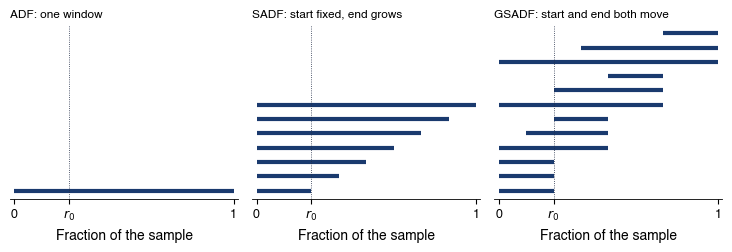

   saved ch17_windows


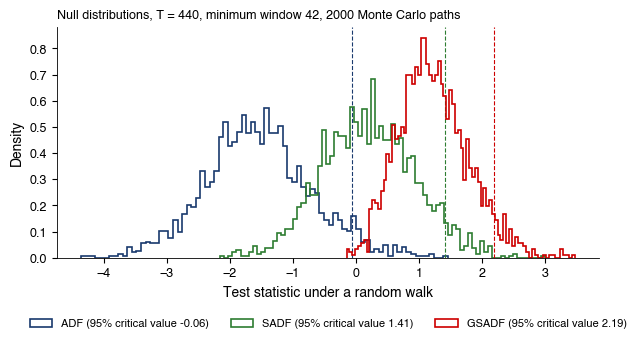

   saved ch17_null
{'adf': {'90': -0.44019069100256664, '95': -0.06104151866652127, '99': 0.6525273541791642}, 'sadf': {'90': 1.1674363323454702, '95': 1.4103426039958415, '99': 1.975277982512124}, 'gsadf': {'90': 1.9614984190261007, '95': 2.187861617328365, '99': 2.64984740456162}}


In [6]:
fig_windows()
res = psy(np.zeros(441))
cv = psy_cv(440, res['w0'], R_MC, SEED)
fig_null(cv, 440)
print({k: cv[k] for k in ['adf', 'sadf', 'gsadf']})

![ch17_windows](./ch17_windows.png)

Output: `ch17_windows.pdf`

![ch17_null](./ch17_null.png)

Output: `ch17_null.pdf`